# 3. The Abilene Traffic Trace

CarlaGym ships one trace of real traffic: a week of the Abilene research backbone,
from [SNDlib](https://sndlib.put.poznan.pl)'s dynamic traffic matrices (measurements by
Yin Zhang). It is a `step,src,dst,volume` table: 2,016 five-minute bins (Monday
1 March to Sunday 7 March 2004), demands in Mbit/s between Abilene's 12 routers.
Provenance, citations and terms: `data/ABILENE_TRACE.md`.

The simulator uses SNDlib's Abilene topology for it (`topology="abilene"`):
12 routers, 15 links, one of them (Atlanta-Indianapolis) at a quarter of the others'
capacity. `TraceTrafficGenerator` rescales the volumes to a chosen mean load and turns
each demand into a Poisson number of packets; with `random_start=True` each episode
starts at a random point of the week.

Two earlier traces (a packet capture and a course dataset) were removed in 0.4.x
because their origin and licence could not be established.

In [1]:
import sys, os
REPO_ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)
os.chdir(REPO_ROOT)

import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
%matplotlib inline

from carla_gym.core.network import ABILENE_NODES, NetworkModel
from carla_gym.core.trace_traffic import TraceTrafficGenerator
from carla_gym.env import CarlaGymEnv
plt.rcParams["figure.dpi"] = 100

TRACE = "data/abilene_trace_20040301_7d.csv.gz"
df = pd.read_csv(TRACE)
df.head()

,step,src,dst,volume
0,0,0,1,0.5222
1,0,0,2,1.6413
2,0,0,3,0.3357
3,0,0,4,0.4130
4,0,0,5,0.4899


## What is in the trace

In [2]:
per_step = df.groupby("step")["volume"].sum()
pd.Series({
    "time bins (5 min)": df["step"].nunique(),
    "days": df["step"].nunique() / 288,
    "source-destination pairs": df.groupby(["src", "dst"]).ngroups,
    "mean total demand (Mbit/s)": round(per_step.mean(), 1),
    "lowest bin (Mbit/s)": round(per_step.min(), 1),
    "highest bin (Mbit/s)": round(per_step.max(), 1),
    "peak / mean": round(per_step.max() / per_step.mean(), 2),
})

time bins (5 min)             2016.00
days                             7.00
source-destination pairs       132.00
mean total demand (Mbit/s)    2989.40
lowest bin (Mbit/s)           1823.90
highest bin (Mbit/s)          6246.50
peak / mean                      2.09
dtype: float64

## Load over the week

Real traffic follows a daily cycle: the total roughly doubles from night to afternoon.
This is why an episode's reward depends on which part of the week it samples, and why
policies are compared on the same seeds (paired), not by their raw rewards alone.

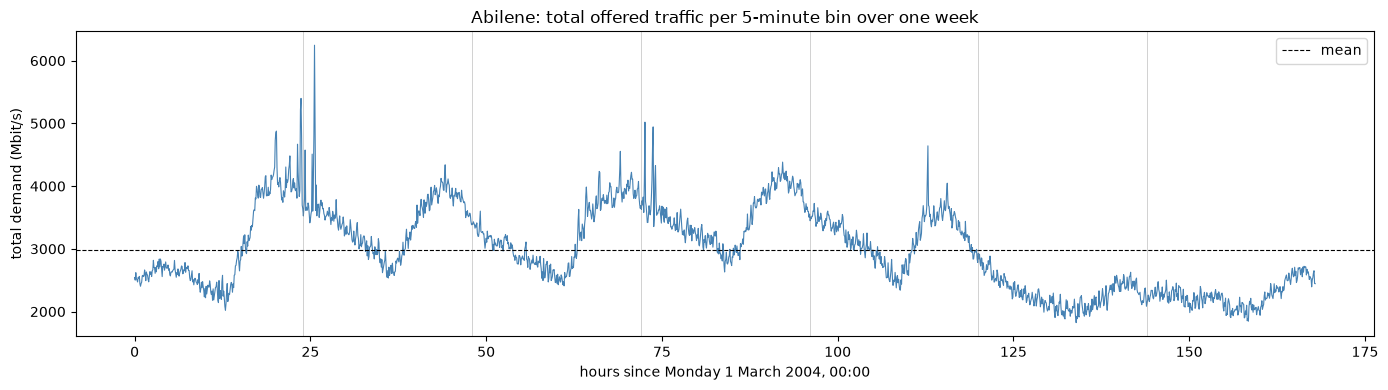

In [3]:
hours = per_step.index * 5 / 60
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(hours, per_step.values, lw=0.8, color="steelblue")
ax.axhline(per_step.mean(), ls="--", color="black", lw=0.8, label="mean")
for d in range(1, 7):
    ax.axvline(24 * d, color="gray", lw=0.5, alpha=0.5)
ax.set_xlabel("hours since Monday 1 March 2004, 00:00"); ax.set_ylabel("total demand (Mbit/s)")
ax.set_title("Abilene: total offered traffic per 5-minute bin over one week")
ax.legend(); plt.tight_layout(); plt.show()

## Which router pairs carry the load

Unlike the synthetic generator, which spreads demand evenly over all pairs, real traffic
is concentrated on a few pairs.

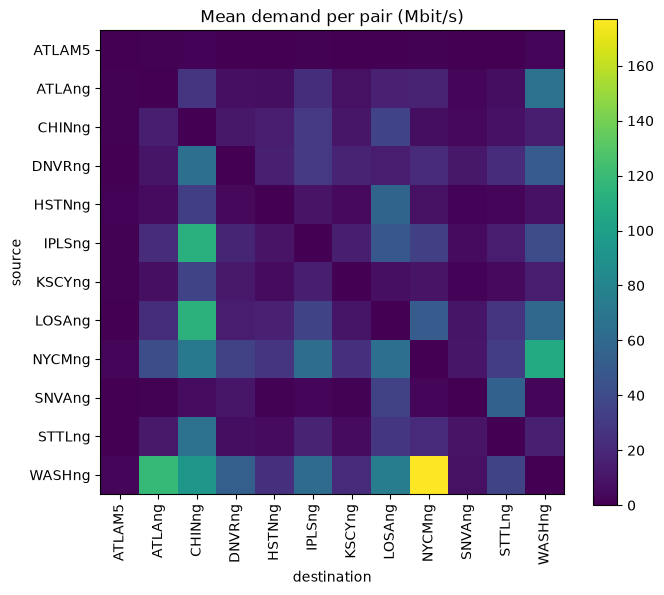

the busiest 10% of pairs (13) carry 40% of the traffic


In [4]:
mat = df.groupby(["src", "dst"])["volume"].mean().unstack(fill_value=0.0).reindex(index=range(12), columns=range(12), fill_value=0.0)
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(mat.values, cmap="viridis")
ax.set_xticks(range(12)); ax.set_xticklabels(ABILENE_NODES, rotation=90)
ax.set_yticks(range(12)); ax.set_yticklabels(ABILENE_NODES)
ax.set_xlabel("destination"); ax.set_ylabel("source")
ax.set_title("Mean demand per pair (Mbit/s)")
fig.colorbar(im, ax=ax); plt.tight_layout(); plt.show()
share = mat.values.flatten(); share = np.sort(share)[::-1] / share.sum()
print(f"the busiest 10% of pairs ({int(0.1 * 132)}) carry {100 * share[:13].sum():.0f}% of the traffic")

## The topology

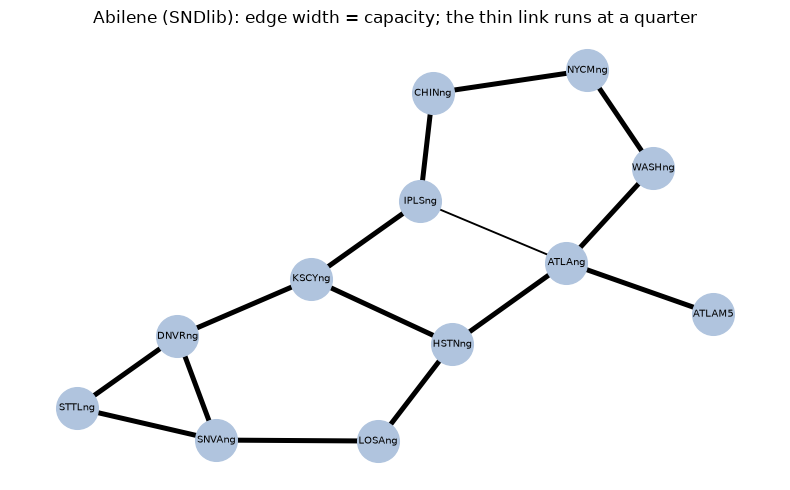

In [5]:
net = NetworkModel("abilene", 12, link_capacity=30.0)
g = net.graph
pos = nx.kamada_kawai_layout(g)
caps = dict(zip(net.edge_list(), net.get_edge_capacities()))
fig, ax = plt.subplots(figsize=(8, 5))
nx.draw_networkx_nodes(g, pos, node_color="lightsteelblue", node_size=900, ax=ax)
nx.draw_networkx_labels(g, pos, labels={i: n for i, n in enumerate(ABILENE_NODES)}, font_size=7, ax=ax)
nx.draw_networkx_edges(g, pos, width=[0.6 + caps[e] / 10 for e in net.edge_list()], edgelist=net.edge_list(), ax=ax)
ax.set_title("Abilene (SNDlib): edge width = capacity; the thin link runs at a quarter")
ax.axis("off"); plt.tight_layout(); plt.show()

## The trace through the simulator

The training scenario: mean load 120, budget 0.8, random episode starts. The same test
seeds give every policy the same traffic, so the comparison is paired.

In [6]:
from carla_gym.baselines import POLICIES, policy_rng
from carla_gym.utils.qos import EpisodeQoS

rows = []
for name in ["max_bandwidth", "queue_proportional", "load_aware_routing", "congestion_aware"]:
    for seed in range(2000, 2005):
        traffic = TraceTrafficGenerator(list(range(12)), TRACE, target_load=120.0, seed=seed, random_start=True)
        env = CarlaGymEnv(topology="abilene", num_nodes=12, bandwidth_budget=0.8, max_steps=200, traffic=traffic, seed=seed)
        obs, _ = env.reset(seed=seed)
        rng, qos, rew = policy_rng(seed), EpisodeQoS(), []
        for t in range(200):
            obs, r, _, _, info = env.step(POLICIES[name](env, obs, rng))
            if t >= 20:
                qos.add(info); rew.append(r)
        rows.append({"policy": name, "seed": seed, "start bin": traffic.offset, "reward": np.mean(rew),
                     **qos.summary()})
res = pd.DataFrame(rows)
res.groupby("policy")[["reward", "delivered_fraction", "dropped_fraction", "latency_delivered"]].mean().sort_values("reward", ascending=False).round(3)

,reward,delivered_fraction,dropped_fraction,latency_delivered
policy,,,,
congestion_aware,0.271,0.835,0.167,4.835
load_aware_routing,0.157,0.787,0.217,5.241
queue_proportional,-0.099,0.692,0.310,5.086
max_bandwidth,-0.281,0.636,0.368,5.102


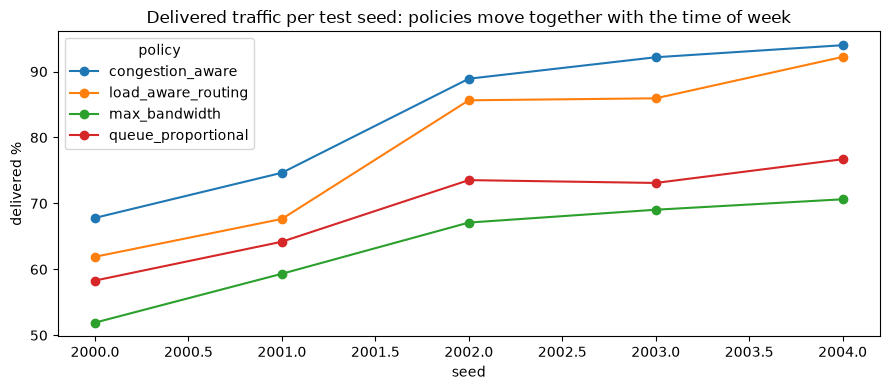

,seed,start bin,start (hours)
15,2000,474,39.500000
16,2001,41,3.416667
17,2002,1703,141.916667
18,2003,1606,133.833333
19,2004,1431,119.250000


In [7]:
piv = res.pivot(index="seed", columns="policy", values="delivered_fraction") * 100
ax = piv.plot(marker="o", figsize=(9, 4))
ax.set_ylabel("delivered %"); ax.set_title("Delivered traffic per test seed: policies move together with the time of week")
plt.tight_layout(); plt.show()
res[res.policy == "congestion_aware"][["seed", "start bin"]].assign(**{"start (hours)": lambda x: x["start bin"] * 5 / 60})

## Building a trace yourself

* The Abilene trace is rebuilt from SNDlib's archive with
  `scripts/prepare_sndlib_trace.py` (other weeks: change `--start`).
* Your own flow logs or packet captures can be converted with
  `scripts/prepare_trace.py` and the adapters in `carla_gym/core/dataset_adapters.py`.
  Keep raw and private data outside version control (`data/raw/` is git-ignored).